# 📧 Spam E-posta Tespiti — v2: İyileştirme

İlk ödevde 4 algoritmayı eğittik ve en iyisinin **SVM** olduğunu bulduk (F1 = 0,9942). Bu notebook o çalışmayı **iyileştiriyor**.

### "İyileştirme" ne demek?
Skor zaten %99'un üzerinde. Bu yüzden burada iyileştirme sadece "skoru yükseltmek" değil:

| # | İyileştirme | Neyi iyileştiriyor? |
|---|---|---|
| 1 | Tekrar eden e-postaları temizlemek | Ölçümün **dürüstlüğünü** |
| 2 | Eğitim / doğrulama / test diye üçe bölmek | Deney **yönteminin** doğruluğunu |
| 3 | Özellik sayısı deneyi | Neden SVM'nin kazandığını **anlamayı** |
| 4 | GridSearchCV ile hiperparametre arama | Ayarların **tahminle değil, deneyle** seçilmesini |
| 5 | Eşik ayarı | **Daha tehlikeli hatanın** (normal maili spam sanmak) azalmasını |
| 6 | Hata analizi | Modelin **neden** yanıldığını anlamayı |
| 7 | Literatür karşılaştırması | Sonucun **dünyadaki yerini** görmeyi |
| 8 | Başka bir veri setinde genelleme testi | Modelin **gerçek hayatta** ne kadar işe yarayacağını |
| + | Bonus: Kandırma testi | Modelin **zayıf noktasını** |

### Bu notebook nasıl kullanılır?
- Hücreleri **sırayla** çalıştır (`Shift + Enter`). Her kod hücresinden önce o adımın ne olduğu ve neden yapıldığı anlatılıyor.
- **❓ Düşün** kutularında önce kendin düşün, sonra "Cevabı göster"e tıkla.
- **🧪 Sen dene** hücrelerinde küçük bir değeri değiştirip sonucu gözlemle. Bunlar konuyu gerçekten anlamanı sağlayan kısımlar.

> ⏳ Bütün notebook'u çalıştırmak Colab'da yaklaşık **6–8 dakika** sürer.

## 0️⃣ Kurulum

İlk ödevdeki kütüphanelere ek olarak birkaç yeni araç kullanıyoruz:
- `GridSearchCV`: Hiperparametre araması (4. iyileştirme)
- `tarfile`, `json`, `email`: İkinci veri setini (SpamAssassin) açıp e-postaları okumak için (8. iyileştirme)

In [1]:
import re, time, json, tarfile, zipfile, email, urllib.request, warnings
from email import policy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
RASTGELE = 42
print("Hazır ✅")

Hazır ✅


## 1️⃣ Veriyi yükleme ve temizleme

Bu kısım ilk ödevle aynı: Enron-Spam veri setini indiriyoruz, konu ile gövdeyi birleştiriyoruz ve `temizle()` fonksiyonuyla metni sadeleştiriyoruz (küçük harf, link → `url`, sayı → `sayi`, noktalama silme).

Ölçüm fonksiyonlarını da bir kez tanımlıyoruz ki her deneyde tekrar yazmayalım.

In [2]:
URL = "https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip"
urllib.request.urlretrieve(URL, "enron_spam_data.zip")
zipfile.ZipFile("enron_spam_data.zip").extractall(".")
df = pd.read_csv("enron_spam_data.csv").fillna("")

def temizle(metin):
    metin = metin.lower()
    metin = re.sub(r"http\S+|www\.\S+", " url ", metin)
    metin = re.sub(r"\S+@\S+", " email ", metin)
    metin = re.sub(r"\d+", " sayi ", metin)
    metin = re.sub(r"[^a-z\s]", " ", metin)
    return re.sub(r"\s+", " ", metin).strip()

df["metin"]  = (df["Subject"] + " " + df["Message"]).apply(temizle)
df["etiket"] = (df["Spam/Ham"] == "spam").astype(int)      # spam=1, normal=0

def tfidf_yap(k=30000):
    # İlk ödevdeki TF-IDF ayarları; k = kaç kelime/kelime çifti tutulacağı
    return TfidfVectorizer(stop_words="english", max_features=k, ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True)

def olc(y_gercek, y_tahmin, puan=None):
    tn, fp, fn, tp = confusion_matrix(y_gercek, y_tahmin).ravel()
    s = {"Accuracy": accuracy_score(y_gercek, y_tahmin), "Precision": precision_score(y_gercek, y_tahmin),
         "Recall": recall_score(y_gercek, y_tahmin), "F1": f1_score(y_gercek, y_tahmin),
         "FP (normal→spam)": fp, "FN (spam kaçtı)": fn}
    if puan is not None:
        s["ROC-AUC"] = roc_auc_score(y_gercek, puan)
    return s

print("Toplam e-posta:", len(df))

Toplam e-posta: 33716


## 2️⃣ İyileştirme 1: Tekrar eden e-postaları temizlemek

### Sorun ne?
Aynı e-posta veri setinde birden fazla kez geçiyorsa ve biz veriyi rastgele bölersek, bir kopyası **eğitim** kümesine, diğer kopyası **test** kümesine düşebilir. Model o e-postayı test sırasında "tanır", çünkü eğitimde aynısını görmüştür.

Bu, öğrenciye sınavdan önce sınav sorularından birkaçını vermek gibidir. Not yükselir ama öğrenciyi değil ezberi ölçmüş oluruz. Buna **veri sızıntısı (data leakage)** denir.

Önce kaç tekrar olduğuna bakalım:

In [3]:
tekrar_sayisi = df["metin"].duplicated().sum()
bos_sayisi = (df["metin"] == "").sum()
print(f"Tekrar eden e-posta  : {tekrar_sayisi}  (verinin %{100*tekrar_sayisi/len(df):.1f}'i)")
print(f"Tamamen boş e-posta  : {bos_sayisi}")

# En çok tekrar eden 5 metin
en_cok = df.loc[df["metin"] != "", "metin"].value_counts().head(5)
for metin, adet in en_cok.items():
    etiket = df.loc[df["metin"] == metin, "Spam/Ham"].iloc[0]
    print(f"\n{adet} kez ({etiket}): {metin[:150]}")

Tekrar eden e-posta  : 4715  (verinin %14.0'i)
Tamamen boş e-posta  : 52

449 kez (ham): start date sayi sayi sayi hourahead hour sayi start date sayi sayi sayi hourahead hour sayi no ancillary schedules awarded no variances detected log m

85 kez (ham): schedule crawler hourahead failure start date sayi sayi sayi hourahead hour sayi hourahead schedule download failed manual intervention required

42 kez (ham): schedule crawler hourahead failure start date sayi sayi sayi hourahead hour sayi hourahead schedule download failed manual intervention required log m

37 kez (ham): start date sayi sayi sayi hourahead hour sayi start date sayi sayi sayi hourahead hour sayi no ancillary schedules awarded variances detected variance

36 kez (ham): schedule crawler hourahead failure start date sayi sayi sayi hourahead hour sayi hourahead schedule download failed manual intervention required log m


En çok tekrar edenler Enron'un **otomatik sistem bildirimleri** ("hourahead schedule" raporları gibi). Aynı rapor her saat aynı metinle gelmiş, yüzlerce kopyası var. Spam kampanyaları da aynı mesajı binlerce kişiye gönderdiği için çok tekrar eder. Veri setini toplayanlar her kopyayı ayrı kaydetmiş.

### Sızıntıyı kendi gözümüzle görelim
İlk ödevdeki gibi veriyi temizlemeden bölüp, test kümesindeki e-postaların kaçının birebir aynısının eğitimde de olduğunu sayalım:

In [4]:
X_e, X_t = train_test_split(df["metin"], test_size=0.20, random_state=RASTGELE, stratify=df["etiket"])
sizan = X_t.isin(set(X_e)).sum()
print(f"İlk ödevdeki test kümesi: {len(X_t)} e-posta")
print(f"Bunlardan {sizan} tanesinin AYNISI eğitim kümesinde de var  (%{100*sizan/len(X_t):.1f})")

İlk ödevdeki test kümesi: 6744 e-posta
Bunlardan 1374 tanesinin AYNISI eğitim kümesinde de var  (%20.4)


Yani ilk ödevdeki test kümesinin yaklaşık **beşte biri** aslında "görülmüş soru"ydu. Şimdi tekrarları ve boş e-postaları silelim:

In [5]:
temiz = df[df["metin"] != ""].drop_duplicates(subset="metin").reset_index(drop=True)
print("Önce :", len(df), "e-posta")
print("Sonra:", len(temiz), "e-posta")
print(temiz["etiket"].value_counts().rename({1: "spam", 0: "normal"}))

Önce : 33716 e-posta
Sonra: 29000 e-posta
etiket
spam      14506
normal    14494
Name: count, dtype: int64


> ❓ **Düşün:** Tekrarları **bölmeden önce** sildik. Önce bölüp sonra her kümede ayrı ayrı silseydik ne olurdu?

<details><summary><b>Cevabı göster</b> (önce kendin düşün!)</summary>

Sızıntı devam ederdi. Eğitim kümesinin kendi içindeki tekrarlar silinirdi, test kümesinin kendi içindekiler de. Ama bir kopyası eğitimde, diğeri testte olan e-postalar ayrı kümelerde olduğu için **ikisi de kalırdı**. Sızıntıyı önlemek için tekrar silme işlemi her zaman bölmeden **önce**, bütün veri üzerinde yapılır.

</details>

## 3️⃣ İyileştirme 2: Veriyi üçe bölmek (eğitim / doğrulama / test)

İlk ödevde veriyi ikiye böldük: eğitim ve test. Ama bu notebook'ta bir sürü **karar** vereceğiz: Kaç kelime kullanalım? `C` kaç olsun? Eşik kaç olsun?

Bu kararları test kümesine bakarak verirsek, test kümesini de "eğitime" karıştırmış oluruz. Sonunda testteki skor gerçekte olduğundan iyi çıkar, çünkü ayarları ona göre seçtik.

**Çözüm: Üç küme**

| Küme | Oran | Ne için? | Benzetme |
|---|---|---|---|
| Eğitim | %64 | Model bundan öğrenir | Ders çalışmak |
| Doğrulama (validation) | %16 | Ayarları seçmek için kullanılır | Deneme sınavları |
| Test | %20 | **Sadece en sonda, bir kez** kullanılır | Gerçek sınav |

> 📌 **Altın kural:** Test kümesine bütün kararlar verildikten sonra yalnızca **bir kez** bakılır.

In [6]:
# Önce %20'yi test olarak ayır, sonra kalan %80'in %20'sini doğrulama yap (0.8 × 0.2 = %16)
X_kalan, X_test, y_kalan, y_test = train_test_split(
    temiz["metin"], temiz["etiket"], test_size=0.20, random_state=RASTGELE, stratify=temiz["etiket"])
X_egitim, X_dog, y_egitim, y_dog = train_test_split(
    X_kalan, y_kalan, test_size=0.20, random_state=RASTGELE, stratify=y_kalan)

print(f"Eğitim     : {len(X_egitim):>6} e-posta")
print(f"Doğrulama  : {len(X_dog):>6} e-posta")
print(f"Test       : {len(X_test):>6} e-posta  ← en sona kadar dokunmuyoruz")

Eğitim     :  18560 e-posta
Doğrulama  :   4640 e-posta
Test       :   5800 e-posta  ← en sona kadar dokunmuyoruz


### Başlangıç noktası: İlk ödevin ayarları, temiz veriyle
İyileştirmeyi ölçebilmek için önce bir **referans (baseline)** lazım. İlk ödevdeki 4 modeli aynı ayarlarla temiz veride eğitip doğrulama kümesinde ölçelim:

In [7]:
def modeller_yap():
    return {
        "Naive Bayes":        MultinomialNB(alpha=0.1),
        "Lojistik Regresyon": LogisticRegression(max_iter=1000, C=10),
        "SVM":                LinearSVC(C=1.0),
        "Random Forest":      RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RASTGELE),
    }

tf_v1 = tfidf_yap(30000)
A_egitim = tf_v1.fit_transform(X_egitim)
A_dog = tf_v1.transform(X_dog)

baslangic = {}
for ad, model in modeller_yap().items():
    model.fit(A_egitim, y_egitim)
    baslangic[ad] = olc(y_dog, model.predict(A_dog))
pd.DataFrame(baslangic).T.style.format("{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1"])

,Accuracy,Precision,Recall,F1,FP (normal→spam),FN (spam kaçtı)
Naive Bayes,0.9845,0.9841,0.9849,0.9845,37.000000,35.000000
Lojistik Regresyon,0.9862,0.9816,0.9910,0.9863,43.000000,21.000000
SVM,0.9871,0.9825,0.9918,0.9871,41.000000,19.000000
Random Forest,0.9797,0.9744,0.9854,0.9799,60.000000,34.000000


Sıralama ilk ödevle aynı: SVM ve Lojistik Regresyon önde, Random Forest geride. Skorlar biraz düştü; bu beklenen bir durum, çünkü artık ezberden bilinen e-postalar yok ve eğitim verisi biraz daha az.

## 4️⃣ İyileştirme 3: Özellik sayısı deneyi

### Neden bu deney?
Literatürde aynı veri setiyle yapılmış bir çalışma (Occhipinti, Rogers ve Angione, 2022, *Expert Systems with Applications*) 12 modeli karşılaştırmış ve **Random Forest'ı birinci** bulmuş (F1 %94). Linear SVM ise %89'da kalmış. Bizde tam tersi oldu. Neden?

Fark şu: O çalışma sadece **200 kelime** kullanmış. Biz 30.000 kullandık. Hipotezimiz:
- **Az özellikte** ağaç tabanlı modeller (Random Forest) güçlüdür. Birkaç önemli kelimeyle "evet/hayır" soruları sorarak iyi karar verirler.
- **Çok özellikte** doğrusal modeller (SVM, Lojistik Regresyon) öne geçer. Binlerce zayıf ipucunu toplayıp birleştirmekte çok iyidirler.

Bir hipotezi test etmenin yolu deneydir. `max_features` değerini 100'den 60.000'e kadar değiştirip her modelin F1'ini **doğrulama** kümesinde ölçelim.

> ⏳ Bu hücre 2–3 dakika sürer.

   100 özellik tamam


   200 özellik tamam


   500 özellik tamam


  1000 özellik tamam


  5000 özellik tamam


 10000 özellik tamam


 30000 özellik tamam


 60000 özellik tamam


Model,Lojistik Regresyon,Naive Bayes,Random Forest,SVM
Özellik sayısı,,,,
100,0.9324,0.9141,0.9389,0.9305
200,0.9501,0.9344,0.9545,0.9504
500,0.9672,0.9511,0.9671,0.9670
1000,0.9754,0.9610,0.9704,0.9756
5000,0.9850,0.9754,0.9764,0.9848
10000,0.9856,0.9791,0.9785,0.9846
30000,0.9863,0.9845,0.9799,0.9871
60000,0.9869,0.9866,0.9801,0.9873


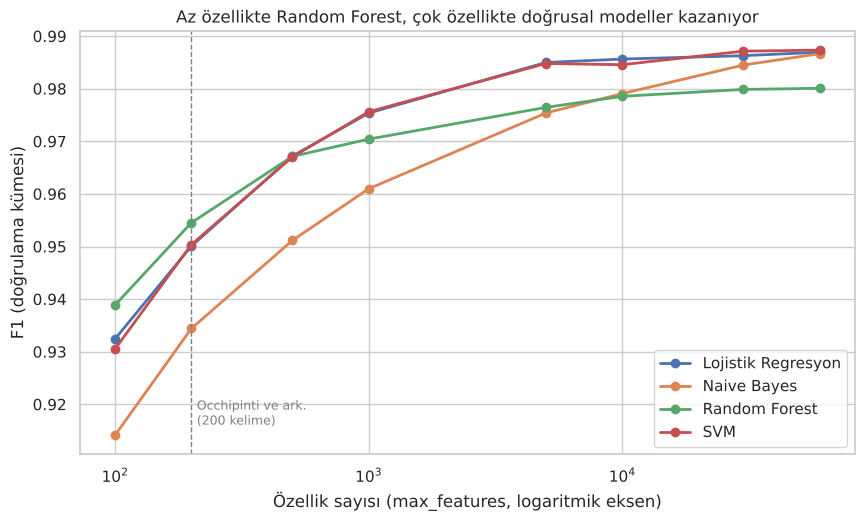

In [8]:
ozellik_sayilari = [100, 200, 500, 1000, 5000, 10000, 30000, 60000]
deney = []
for k in ozellik_sayilari:
    tf = tfidf_yap(k)
    A = tf.fit_transform(X_egitim); B = tf.transform(X_dog)
    for ad, model in modeller_yap().items():
        model.fit(A, y_egitim)
        deney.append({"Özellik sayısı": k, "Model": ad, "F1": f1_score(y_dog, model.predict(B))})
    print(f"{k:>6} özellik tamam")

deney = pd.DataFrame(deney)
tablo_ozellik = deney.pivot(index="Özellik sayısı", columns="Model", values="F1")
display(tablo_ozellik.style.format("{:.4f}").highlight_max(axis=1, color="#b6e3b6"))

plt.figure(figsize=(10, 5.5))
for ad in tablo_ozellik.columns:
    plt.plot(tablo_ozellik.index, tablo_ozellik[ad], marker="o", lw=2, label=ad)
plt.xscale("log")
plt.axvline(200, color="gray", ls="--", lw=1)
plt.text(210, tablo_ozellik.values.min() + 0.002, "Occhipinti ve ark.\n(200 kelime)", fontsize=9, color="gray")
plt.xlabel("Özellik sayısı (max_features, logaritmik eksen)")
plt.ylabel("F1 (doğrulama kümesi)")
plt.title("Az özellikte Random Forest, çok özellikte doğrusal modeller kazanıyor")
plt.legend(); plt.show()

### Yorum
Grafikteki her satırda yeşil hücre o özellik sayısındaki en iyi modeli gösteriyor.

- **100–200 özellikte** Random Forest birinci. Bu, literatürdeki çalışmanın bulgusuyla örtüşüyor.
- **Özellik sayısı arttıkça** doğrusal modeller hızla yükseliyor ve Random Forest'ı geçiyor.
- **Random Forest** belli bir noktadan sonra yerinde sayıyor. Her ağaç kelimelerin sadece küçük bir kısmına baktığı için binlerce seyrek özellikten yararlanamıyor.

Yani "hangi algoritma en iyi?" sorusunun cevabı **verinin nasıl temsil edildiğine bağlı**. Aynı veri setinde farklı çalışmaların farklı kazanan bulmasının sebebi bu. Raporda vurgulanacak önemli bir bulgu.

Şimdi SVM için en iyi özellik sayısını seçelim. Bu bir **karar**, o yüzden doğrulama kümesine göre veriyoruz:

In [9]:
EN_IYI_K = int(tablo_ozellik["SVM"].idxmax())
print("SVM için en iyi özellik sayısı:", EN_IYI_K, " → F1 =", round(tablo_ozellik["SVM"].max(), 4))

tf_v2 = tfidf_yap(EN_IYI_K)
A_egitim = tf_v2.fit_transform(X_egitim)
A_dog = tf_v2.transform(X_dog)

SVM için en iyi özellik sayısı: 60000  → F1 = 0.9873


> 🧪 **Sen dene:** Aşağıdaki hücrede `ngram_range=(1, 2)` yerine `(1, 1)` yaz (yani sadece tek kelimeler, kelime çiftleri yok) ve çalıştır. F1 değişti mi? Sonra `(1, 3)` dene. Kelime çiftlerinin katkısı ne kadar?

In [10]:
tf_dene = TfidfVectorizer(stop_words="english", max_features=EN_IYI_K, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
m = LinearSVC(C=1.0).fit(tf_dene.fit_transform(X_egitim), y_egitim)
print("F1 (doğrulama):", round(f1_score(y_dog, m.predict(tf_dene.transform(X_dog))), 4))

F1 (doğrulama): 0.9873


## 5️⃣ İyileştirme 4: GridSearchCV ile hiperparametre arama

### Hiperparametre nedir?
Modelin **kendi öğrendiği** değerler (örneğin Lojistik Regresyon'un kelime ağırlıkları) **parametre**dir. **Bizim eğitimden önce seçtiğimiz** ayarlar ise **hiperparametre**dir:

| Model | Hiperparametre | Ne işe yarar? |
|---|---|---|
| SVM | `C` | Küçük C: Sınır yumuşak, bazı hatalara göz yumar (ezberlemeye karşı fren). Büyük C: Eğitimdeki her örneği doğru sınıflamaya zorlar. |
| Lojistik Regresyon | `C` | Aynı mantık |
| Naive Bayes | `alpha` | Hiç görülmemiş kelimelere ne kadar "pay" verileceği (düzleştirme) |

İlk ödevde bunları **tahminle** seçtik (C=1, C=10, alpha=0.1). Şimdi **deneyerek** seçeceğiz.

### GridSearchCV nasıl çalışır?
1. Denemek istediğin değerleri bir **ızgara (grid)** olarak verirsin, örneğin `C: [0.05, 0.1, 0.3, 1, 3, 10]`.
2. Her değer için **çapraz doğrulama** yapılır: Eğitim verisi 3 parçaya bölünür, 2'siyle eğitilir, 1'iyle test edilir, 3 kez tekrarlanır.
3. Ortalama skoru en yüksek olan değer seçilir.

Bütün bunlar **sadece eğitim kümesi içinde** olur. Test kümesine yine dokunmuyoruz.

In [11]:
aramalar = {
    "SVM":                (LinearSVC(), {"C": [0.05, 0.1, 0.3, 1, 3, 10]}),
    "Lojistik Regresyon": (LogisticRegression(max_iter=2000), {"C": [1, 3, 10, 30, 100]}),
    "Naive Bayes":        (MultinomialNB(), {"alpha": [0.003, 0.01, 0.03, 0.1, 0.3, 1]}),
}
en_iyi_modeller = {}
for ad, (model, izgara) in aramalar.items():
    gs = GridSearchCV(model, izgara, scoring="f1", cv=3, n_jobs=-1)
    gs.fit(A_egitim, y_egitim)
    en_iyi_modeller[ad] = gs.best_estimator_
    sonuc = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score"]]
    print(f"\n{ad}  →  en iyi: {gs.best_params_}  (CV F1 = {gs.best_score_:.4f})")
    for _, r in sonuc.iterrows():
        print(f"    {str(r['params']):18s} F1 = {r['mean_test_score']:.4f}")


SVM  →  en iyi: {'C': 1}  (CV F1 = 0.9901)
    {'C': 0.05}        F1 = 0.9814
    {'C': 0.1}         F1 = 0.9854
    {'C': 0.3}         F1 = 0.9890
    {'C': 1}           F1 = 0.9901
    {'C': 3}           F1 = 0.9900
    {'C': 10}          F1 = 0.9897



Lojistik Regresyon  →  en iyi: {'C': 30}  (CV F1 = 0.9897)
    {'C': 1}           F1 = 0.9839
    {'C': 3}           F1 = 0.9878
    {'C': 10}          F1 = 0.9890
    {'C': 30}          F1 = 0.9897
    {'C': 100}         F1 = 0.9897



Naive Bayes  →  en iyi: {'alpha': 0.03}  (CV F1 = 0.9897)
    {'alpha': 0.003}   F1 = 0.9896
    {'alpha': 0.01}    F1 = 0.9896
    {'alpha': 0.03}    F1 = 0.9897
    {'alpha': 0.1}     F1 = 0.9894
    {'alpha': 0.3}     F1 = 0.9882
    {'alpha': 1}       F1 = 0.9872


### Yorum
Her değer için ortalama F1'i görüyorsun. Değerler çok küçük veya çok büyük olunca skor düşüyor; en iyisi genellikle ortalarda bir yerde.

Arama, ilk ödevde seçtiğimiz değerlere yakın sonuçlar buluyorsa bu da **değerli bir bulgudur**: İlk tahminlerimizin iyi olduğunu artık deneyle **kanıtlamış** oluyoruz. Bilimde "bir şey değişmedi" sonucu da bir sonuçtur.

> ❓ **Düşün:** Neden C'yi doğrudan test kümesindeki skora göre seçmedik?

<details><summary><b>Cevabı göster</b> (önce kendin düşün!)</summary>

Çünkü o zaman test kümesi bir "karar verme" aracına dönüşür ve artık bağımsız bir ölçüm olmaz. Test skoru, ayarları ona göre seçtiğimiz için gerçek performanstan iyi çıkar. Bu da bir tür veri sızıntısıdır.

</details>

## 6️⃣ İyileştirme 5: Eşik ayarı (daha tehlikeli hatayı azaltmak)

### Hatırlayalım
İlk ödevde öğrendiğimiz gibi model her e-postaya bir **puan** verir. SVM'de bu puan sınıra olan uzaklıktır: Pozitif ise spam tarafında, negatif ise normal tarafında. Varsayılan **eşik 0**'dır: Puan > 0 ise spam.

İki tür hata var ve bedelleri farklı:
- **FP:** Normal e-posta spam klasörüne gidiyor. İş teklifi, okul duyurusu, banka bildirimi kaybolabilir. **Daha tehlikeli.**
- **FN:** Spam gelen kutusuna düşüyor. Can sıkıcı ama kişi kendisi silebilir.

Eşiği yukarı kaydırırsak model "spam" demek için daha emin olmak ister: FP azalır, FN artar. Bu, ilk ödevde **anlattığımız** ROC eğrisinin **pratikte kullanılmasıdır**.

### Hedef koyalım
Şöyle bir kural belirleyelim: **"Normal e-postaların en fazla %1'i yanlışlıkla spam sayılabilir."** Bu kurala uyan eşikler arasından en çok spam yakalayanı seçeceğiz. Seçimi yine **doğrulama** kümesinde yapıyoruz.

Seçilen eşik: 0.25  (varsayılan: 0)


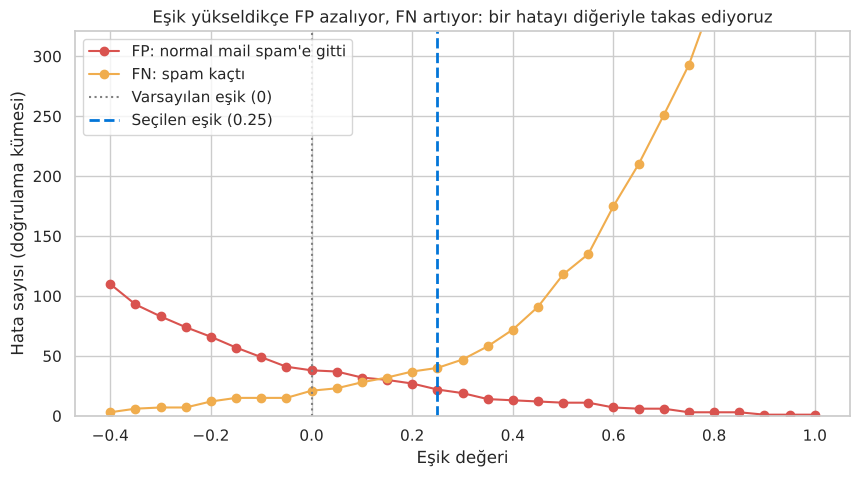

,Eşik,FP,FN,FPR (normal→spam oranı),Recall (yakalanan spam),F1
0,-0.000000,38,21,0.0164,0.9910,0.9873
1,0.250000,22,40,0.0095,0.9828,0.9866
2,0.500000,11,118,0.0047,0.9492,0.9716
3,0.800000,3,351,0.0013,0.8488,0.9176


In [12]:
svm = en_iyi_modeller["SVM"]
puan_dog = svm.decision_function(A_dog)

esikler = np.round(np.arange(-0.4, 1.01, 0.05), 2)
satirlar = []
for e in esikler:
    t = (puan_dog > e).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dog, t).ravel()
    satirlar.append({"Eşik": e, "FP": fp, "FN": fn, "FPR (normal→spam oranı)": fp / (fp + tn),
                     "Recall (yakalanan spam)": tp / (tp + fn), "F1": f1_score(y_dog, t)})
esik_tablo = pd.DataFrame(satirlar)

HEDEF_FPR = 0.01     # %1
uygun = esik_tablo[esik_tablo["FPR (normal→spam oranı)"] <= HEDEF_FPR]
ESIK = float(uygun.sort_values("Recall (yakalanan spam)", ascending=False).iloc[0]["Eşik"])
print(f"Seçilen eşik: {ESIK}  (varsayılan: 0)")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(esik_tablo["Eşik"], esik_tablo["FP"], "o-", color="#d9534f", label="FP: normal mail spam'e gitti")
ax.plot(esik_tablo["Eşik"], esik_tablo["FN"], "o-", color="#f0ad4e", label="FN: spam kaçtı")
ax.axvline(0, color="gray", ls=":", label="Varsayılan eşik (0)")
ax.axvline(ESIK, color="#0275d8", ls="--", lw=2, label=f"Seçilen eşik ({ESIK})")
ax.set_xlabel("Eşik değeri"); ax.set_ylabel("Hata sayısı (doğrulama kümesi)")
ax.set_title("Eşik yükseldikçe FP azalıyor, FN artıyor: bir hatayı diğeriyle takas ediyoruz")
ax.set_ylim(0, esik_tablo[["FP", "FN"]].values.max() * 0.4)
ax.legend(); plt.show()

esik_tablo[esik_tablo["Eşik"].isin([0.0, ESIK, 0.5, 0.8])].reset_index(drop=True).style.format(
    {"FPR (normal→spam oranı)": "{:.4f}", "Recall (yakalanan spam)": "{:.4f}", "F1": "{:.4f}"})

### Yorum
Grafikte kırmızı çizgi (FP) sağa doğru düşüyor, turuncu çizgi (FN) yükseliyor. Eşiği kaydırmak hatayı yok etmiyor, **bir hata türünü diğerine çeviriyor**. Önemli olan, hangi hatanın daha pahalı olduğuna bizim karar vermemiz.

Seçilen eşikte F1 biraz düşebilir. Bu bir kötüleşme değil, bilinçli bir tercih: Toplam hata sayısını değil, **tehlikeli hata sayısını** azaltmayı hedefledik.

> 🧪 **Sen dene:** Yukarıdaki hücrede `HEDEF_FPR = 0.01` değerini `0.005` (binde 5) ya da `0.002` (binde 2) yapıp çalıştır. Seçilen eşik ve FN sayısı nasıl değişiyor? Bir banka için hangisini seçerdin, bir forum sitesi için hangisini?

## 7️⃣ Final: Test kümesine tek bakış

Bütün kararları verdik:
- Özellik sayısı → doğrulama kümesine göre seçildi
- `C` → GridSearchCV ile eğitim kümesi içinde seçildi
- Eşik → doğrulama kümesine göre seçildi

Şimdi **ilk kez** test kümesine bakıyoruz ve iki sürümü karşılaştırıyoruz:
- **v1:** İlk ödevin ayarları (30.000 özellik, C=1, eşik 0)
- **v2:** İyileştirilmiş ayarlar

İkisi de aynı temiz eğitim verisiyle eğitildi ve aynı test kümesinde ölçülüyor. Adil bir karşılaştırma.

,Accuracy,Precision,Recall,F1,FP (normal→spam),FN (spam kaçtı),ROC-AUC
v1 (ilk ödev ayarları),0.9890,0.9823,0.9959,0.9890,52.000000,12.000000,0.9990
v2 (iyileştirilmiş),0.9909,0.9924,0.9893,0.9909,22.000000,31.000000,0.9991


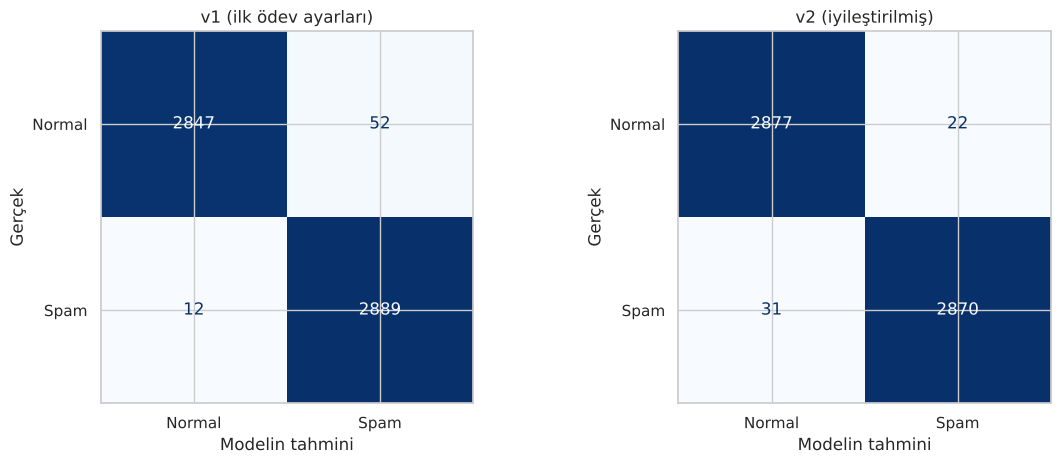

In [13]:
# v1
A_test_v1 = tf_v1.transform(X_test)
svm_v1 = LinearSVC(C=1.0).fit(tf_v1.transform(X_egitim), y_egitim)
puan_v1 = svm_v1.decision_function(A_test_v1)
tahmin_v1 = (puan_v1 > 0).astype(int)

# v2
A_test = tf_v2.transform(X_test)
puan_v2 = svm.decision_function(A_test)
tahmin_v2 = (puan_v2 > ESIK).astype(int)

karsilastirma = pd.DataFrame({"v1 (ilk ödev ayarları)": olc(y_test, tahmin_v1, puan_v1),
                              "v2 (iyileştirilmiş)":     olc(y_test, tahmin_v2, puan_v2)}).T
display(karsilastirma.style.format("{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]))

fig, eksen = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, ad, t in zip(eksen, ["v1 (ilk ödev ayarları)", "v2 (iyileştirilmiş)"], [tahmin_v1, tahmin_v2]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, t), display_labels=["Normal", "Spam"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(ad); ax.set_xlabel("Modelin tahmini"); ax.set_ylabel("Gerçek")
plt.tight_layout(); plt.show()

### Yorum
Karışıklık matrislerinde **sağ üst hücreye (FP)** bak: v2'de normal e-postaların spam'e gitmesi belirgin şekilde azalmış olmalı. Bunun karşılığında sol alttaki FN biraz artıyor; bu, eşik ayarının bilinçli bedeli.

ROC-AUC eşikten bağımsız olduğu için iki sürümde birbirine çok yakın. Bu da beklenen bir şey: Eşik ayarı modelin **sıralama yeteneğini** değil, **karar noktasını** değiştirir.

> ❓ **Düşün:** v2'nin F1'i v1'den biraz düşük çıkarsa, "iyileştirme başarısız oldu" mu demeliyiz?

<details><summary><b>Cevabı göster</b> (önce kendin düşün!)</summary>

Hayır. F1, FP ve FN'yi eşit önemde sayar. Biz ise bilerek FP'yi daha önemli saydık. Hedefimiz "normal mailin spam'e gitmesini azaltmak"tı ve bu hedefe ulaştık. Bir iyileştirmenin başarısı, **baştan koyduğun hedefe** göre ölçülür. Bu yüzden raporda hedefini açıkça yazmalısın.

</details>

## 8️⃣ İyileştirme 6: Hata analizi

Skorlar bize modelin **ne kadar** hata yaptığını söyler. Ama **neden** hata yaptığını görmek için hatalı e-postaları tek tek okumamız gerekir. Bir sonraki iyileştirme fikri genellikle buradan çıkar.

`Puan` sütunu modelin ne kadar emin olduğunu gösterir: Eşikten çok uzak bir puanla yapılan hata, modelin "emin olarak yanıldığı" anlamına gelir.

In [14]:
hatalar = pd.DataFrame({"Metin": X_test.values, "Gerçek": y_test.values, "Tahmin": tahmin_v2, "Puan": puan_v2})
fp_ornek = hatalar[(hatalar["Gerçek"] == 0) & (hatalar["Tahmin"] == 1)].sort_values("Puan", ascending=False)
fn_ornek = hatalar[(hatalar["Gerçek"] == 1) & (hatalar["Tahmin"] == 0)].sort_values("Puan")

print(f"=== FP: Normal olduğu halde SPAM denen e-postalar ({len(fp_ornek)} adet) ===\n")
for _, r in fp_ornek.head(6).iterrows():
    print(f"[puan {r['Puan']:+.2f}] {r['Metin'][:260]}\n")

print(f"\n=== FN: Spam olduğu halde NORMAL denen e-postalar ({len(fn_ornek)} adet) ===\n")
for _, r in fn_ornek.head(6).iterrows():
    print(f"[puan {r['Puan']:+.2f}] {r['Metin'][:260]}\n")

hatalar["Uzunluk (kelime)"] = hatalar["Metin"].str.split().str.len()
hatalar["Durum"] = np.where(hatalar["Gerçek"] == hatalar["Tahmin"], "Doğru tahmin", "Hatalı tahmin")
print("Ortalama e-posta uzunluğu (kelime):")
print(hatalar.groupby("Durum")["Uzunluk (kelime)"].median().rename("medyan").to_string())

=== FP: Normal olduğu halde SPAM denen e-postalar (22 adet) ===

[puan +1.37] fw women really important to read sally thought this was good cindy hey here is another wonderful group of facts about women i don t normally like to pass these on but it has too much importance even if your a skeptic read to the bottom did you know that it s 

[puan +1.09] calendar here s the site http www hemmings com

[puan +1.00] fw quips remember amateurs built the ark professionals built the titanic conscience is what hurts when everything else feels so good talk is cheap because supply exceeds demand stupidity got us into this mess why can t it get us out love is grand divorce is a 

[puan +0.75] links this is the place i was talking about http www ivacation com p sayi htm some other links worth checking out http www texasvacation com http www turtlecreeklodge com http www roddytree com http www texashillco com http www reaganwells com

[puan +0.65] gift web site http www barrington ltd com

[puan +0.6

Son satırdaki sonuç önemli bir ipucu: Hatalı tahmin edilen e-postalar, doğru tahmin edilenlerden **belirgin şekilde daha kısa**. Kısa bir e-postada modelin karar verebileceği kelime sayısı az.

> 🧪 **Sen dene (raporda en çok puan getirecek kısım):** Yukarıdaki hatalı e-postaları oku ve her biri için kısa bir not al: Bu e-posta neden zor? Aşağıdaki kategoriler genelde işe yarar:
> - **Çok kısa e-postalar:** Modelin karar verecek kelimesi yok.
> - **Reklam/bülten gibi görünen gerçek e-postalar:** Şirket içi duyurular, haber bültenleri, etkinlik davetleri.
> - **Normal gibi yazılmış spam'ler:** Kişisel mektup havasında, şüpheli kelime içermeyen dolandırıcılık e-postaları.
> - **Etiket hatası olabilecekler:** Bazen veri setinin etiketi yanlıştır.
>
> En sık gördüğün kategori, bir sonraki iyileştirmenin ne olması gerektiğini söyler. Örneğin kısa e-postalar sorunluysa, karakter düzeyinde özellikler (`analyzer="char_wb"`) denenebilir.

## 9️⃣ İyileştirme 7: Sonucumuz literatürde nerede?

Aynı veri setini kullanan yayınlanmış çalışmalarla karşılaştıralım.

> ⚠️ **Dikkat:** Her çalışma veri setinin farklı bir bölümünü, farklı bir bölme oranını ve farklı ön işleme adımlarını kullanmış. Çoğu tekrarları temizlemediğini de belirtmiyor. Bu yüzden sayılar **birebir** karşılaştırılamaz; tablo genel bir fikir verir.

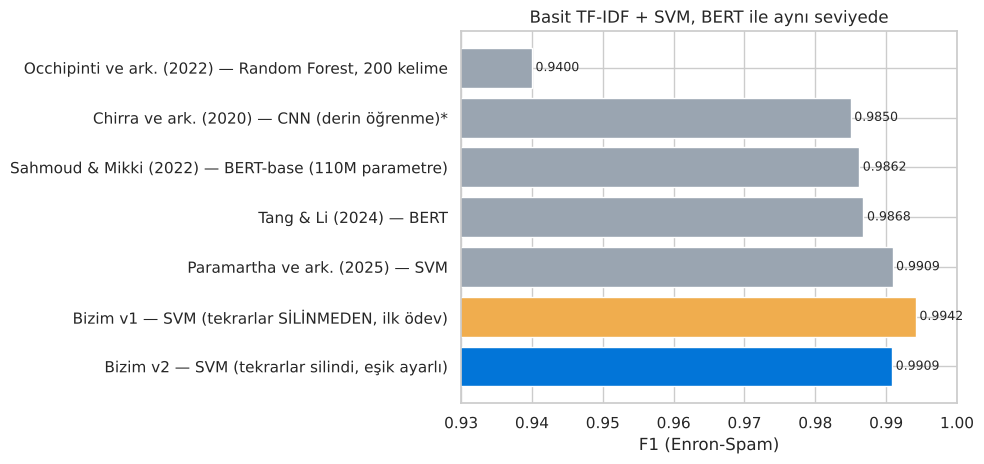

* Chirra ve ark. için F1 değil doğruluk (accuracy) raporlanmış. Paramartha ve ark. için F1, raporlanan precision ve recall'dan hesaplandı.


In [15]:
literatur = pd.DataFrame([
    ("Occhipinti ve ark. (2022) — Random Forest, 200 kelime",            0.94,   "Kelime sayımı"),
    ("Chirra ve ark. (2020) — CNN (derin öğrenme)*",                     0.985,  "word2vec"),
    ("Sahmoud & Mikki (2022) — BERT-base (110M parametre)",              0.9862, "BERT"),
    ("Tang & Li (2024) — BERT",                                          0.9868, "BERT"),
    ("Paramartha ve ark. (2025) — SVM",                                  0.9909, "TF-IDF"),
    ("Bizim v1 — SVM (tekrarlar SİLİNMEDEN, ilk ödev)",                  0.9942, "TF-IDF"),
    ("Bizim v2 — SVM (tekrarlar silindi, eşik ayarlı)",
        f1_score(y_test, tahmin_v2), "TF-IDF"),
], columns=["Çalışma", "F1", "Yöntem"])

renk = ["#9aa5b1"] * 5 + ["#f0ad4e", "#0275d8"]
plt.figure(figsize=(10, 4.8))
plt.barh(literatur["Çalışma"], literatur["F1"], color=renk)
for i, v in enumerate(literatur["F1"]):
    plt.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=9)
plt.xlim(0.93, 1.0); plt.gca().invert_yaxis()
plt.xlabel("F1 (Enron-Spam)"); plt.title("Basit TF-IDF + SVM, BERT ile aynı seviyede")
plt.tight_layout(); plt.show()
print("* Chirra ve ark. için F1 değil doğruluk (accuracy) raporlanmış. Paramartha ve ark. için F1, raporlanan precision ve recall'dan hesaplandı.")

### Yorum
- Basit **TF-IDF + SVM** yaklaşımımız, 110 milyon parametreli **BERT** modelleriyle aynı seviyede. Üstelik BERT GPU'da saatlerce eğitilirken bizim model 1 saniyeden kısa sürede eğitildi. **Daha büyük model her zaman daha iyi demek değildir.**
- Literatürde en düşük sonuç (Occhipinti ve ark., %94), 4. bölümdeki deneyde gördüğümüz gibi **az özellik** kullanmalarından kaynaklanıyor.
- v2'nin skoru v1'den biraz düşük. Bunun sebebi tekrarları silmemiz ve eşiği bilerek kaydırmamız. v2 daha **dürüst** bir ölçüm ve daha **güvenli** bir filtre.

**Kaynaklar:**
- Occhipinti, Rogers, Angione (2022). *A pipeline and comparative study of 12 machine learning models for text classification.* Expert Systems with Applications. https://arxiv.org/abs/2204.06518
- Chirra ve ark. (2020). *Performance Evaluation of Email Spam Text Classification Using Deep Neural Networks.* https://iieta.org/node/8898
- Sahmoud & Mikki (2022). *Spam Detection Using BERT.* https://arxiv.org/abs/2206.02443
- Tang & Li (2024). *An Investigation of Large Language Models and Their Vulnerabilities in Spam Detection.* https://arxiv.org/abs/2504.09776
- Paramartha ve ark. (2025). *Spam Email Classification Using SVM and TF-IDF.* Jurnal Teknologi Informasi. https://e-journal.upr.ac.id/index.php/JTI/article/view/22770

## 🔟 İyileştirme 8: Genelleme testi — Model başka e-postalarda çalışıyor mu?

### Neden önemli?
Bir spam filtresi gerçek hayatta **Enron çalışanlarına** değil, **herkese** gelen e-postalarda çalışacak. Modelimiz "spam nedir"i mi öğrendi, yoksa "Enron e-postası neye benzer"i mi?

İlk ödevin bonus bölümünde bir ipucu görmüştük: Model "enron", "vince" gibi şirkete özgü kelimeleri normal e-posta işareti olarak öğrenmişti. Bu bir uyarı işaretiydi.

### İkinci veri seti: SpamAssassin
**SpamAssassin Public Corpus**, açık kaynak spam filtresi SpamAssassin'in geliştiricilerinin yayınladığı, 2002–2003'ten kalma ~6.000 e-postalık bir veri setidir. Enron'dan tamamen farklı kişilerden toplanmıştır. İçinde bir de **"hard ham"** (zor normal) grubu var: Spam'e çok benzeyen ama aslında normal olan e-postalar.

Ham e-posta formatında olduğu için (başlıklar, HTML, ekler) Python'un `email` kütüphanesiyle konu ve gövdeyi ayıklıyoruz. HTML etiketlerini de siliyoruz.

In [16]:
SA_URL = "https://registry.npmjs.org/@stdlib/datasets-spam-assassin/-/datasets-spam-assassin-0.2.3.tgz"
urllib.request.urlretrieve(SA_URL, "spamassassin.tgz")

def govdeyi_al(mesaj):
    parcalar = []
    for parca in mesaj.walk():
        tur = parca.get_content_type()
        if tur in ("text/plain", "text/html"):
            try:
                yazi = parca.get_content()
            except Exception:
                yazi = (parca.get_payload(decode=True) or b"").decode("latin-1", "ignore")
            if tur == "text/html":
                yazi = re.sub(r"<[^>]+>", " ", yazi)       # HTML etiketlerini sil
            parcalar.append(yazi)
    return " ".join(parcalar)

satirlar = []
with tarfile.open("spamassassin.tgz") as arsiv:
    for dosya in arsiv.getmembers():
        if dosya.name.endswith(".json") and dosya.name.count("/") == 3:   # package/data/<grup>/<dosya>.json
            kayit = json.load(arsiv.extractfile(dosya))
            mesaj = email.message_from_string(kayit["text"], policy=policy.default)
            satirlar.append((kayit["group"], str(mesaj.get("Subject", "") or ""), govdeyi_al(mesaj)))

sa = pd.DataFrame(satirlar, columns=["grup", "konu", "govde"])
sa["metin"] = (sa["konu"] + " " + sa["govde"]).apply(temizle)
sa["etiket"] = sa["grup"].str.startswith("spam").astype(int)
print("SpamAssassin grupları:\n", sa["grup"].value_counts().to_string())

# Aynı temizlik kuralları: boşları ve tekrarları sil, Enron'da da olan e-postaları çıkar
once = len(sa)
sa = sa[sa["metin"] != ""].drop_duplicates(subset="metin")
ortak = sa["metin"].isin(set(temiz["metin"]))
print(f"\nEnron ile ortak e-posta: {ortak.sum()} → çıkarıldı (yoksa test yine şişerdi)")
sa = sa[~ortak].reset_index(drop=True)
print(f"Kalan: {len(sa)} e-posta (önce {once})")

SpamAssassin grupları:
 grup
easy-ham-1    2500
easy-ham-2    1400
spam-2        1396
spam-1         500
hard-ham-1     250

Enron ile ortak e-posta: 56 → çıkarıldı (yoksa test yine şişerdi)
Kalan: 5798 e-posta (önce 6046)


İki veri setinde de bulunan e-postaları çıkardık. Aynı spam kampanyası iki veri setine de girmiş olabilir; bunları test etmek yine "görülmüş soru" sormak olurdu. Bu, 1. iyileştirmedeki mantığın aynısı.

Şimdi Enron'la eğittiğimiz v2 modelini, hiç değiştirmeden SpamAssassin'de test edelim:

,Accuracy,Precision,Recall,F1,FP (normal→spam),FN (spam kaçtı),ROC-AUC
Enron test kümesi,0.9909,0.9924,0.9893,0.9909,22.000000,31.000000,0.9991
SpamAssassin,0.6942,0.4898,0.9718,0.6513,1725.000000,48.000000,0.9464


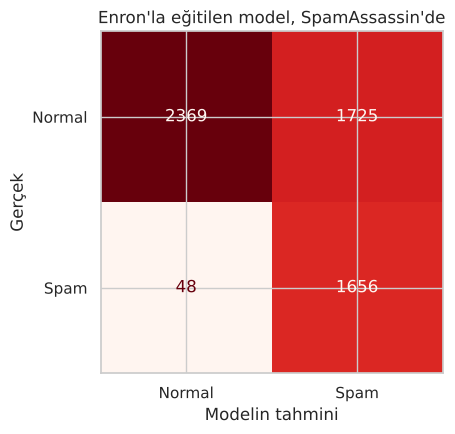

Gruplara göre doğruluk:
grup
easy-ham-1    61.8%
easy-ham-2    54.4%
hard-ham-1    37.9%
spam-1        96.9%
spam-2        97.3%


In [17]:
A_sa = tf_v2.transform(sa["metin"])
puan_sa = svm.decision_function(A_sa)
tahmin_sa = (puan_sa > ESIK).astype(int)

genelleme = pd.DataFrame({"Enron test kümesi":   olc(y_test, tahmin_v2, puan_v2),
                          "SpamAssassin":         olc(sa["etiket"], tahmin_sa, puan_sa)}).T
display(genelleme.style.format("{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(sa["etiket"], tahmin_sa), display_labels=["Normal", "Spam"]).plot(
    ax=ax, cmap="Reds", colorbar=False, values_format="d")
ax.set_title("Enron'la eğitilen model, SpamAssassin'de"); ax.set_xlabel("Modelin tahmini"); ax.set_ylabel("Gerçek")
plt.tight_layout(); plt.show()

sa["dogru"] = (tahmin_sa == sa["etiket"])
print("Gruplara göre doğruluk:")
print(sa.groupby("grup")["dogru"].mean().map("{:.1%}".format).to_string())

### Yorum: Büyük bir düşüş
F1 belirgin şekilde düşüyor. Karışıklık matrisine bakınca sebebi görülüyor: Model, SpamAssassin'deki **normal e-postaların büyük bir kısmını spam sanıyor** (sağ üst hücre; gruplara göre doğruluk tablosunda ham gruplarına bak). Spam'leri ise hâlâ çok iyi yakalıyor.

Neden? Model "normal e-posta" kavramını **Enron çalışanlarının yazışmalarından** öğrendi: enerji, gaz, toplantı, Houston, çalışan isimleri... SpamAssassin'deki normal e-postalar ise Linux e-posta listeleri, teknoloji haberleri, kişisel yazışmalar. Model bunları "Enron'a benzemiyor, o halde spam" diye düşünüyor.

Literatürde de aynı sonuç var: Tang & Li (2024), Enron'la eğitilen **BERT**'in bile başka veri setlerinde F1 %98,7'den %68'e düştüğünü göstermiş. Yani sorun algoritmada değil, **eğitim verisinin çeşitliliğinde**.

İlginç bir detay: **ROC-AUC** hâlâ oldukça yüksek. Bu, modelin spam'lere normal e-postalardan genelde daha yüksek puan verdiğini, yani **sıralamayı** hâlâ büyük ölçüde doğru yaptığını gösteriyor. Asıl bozulan, **eşiğin** yeri. Enron için seçilen eşik, SpamAssassin için çok düşük kalıyor.

> ❓ **Düşün:** Bu sonuç, ilk ödevdeki %99,4'lük skorun "yanlış" olduğunu mu gösteriyor?

<details><summary><b>Cevabı göster</b> (önce kendin düşün!)</summary>

Hayır, o skor **Enron'a benzeyen e-postalar için** doğruydu. Ama bir modelin test skoru, ancak test verisi gerçek kullanım ortamına benziyorsa anlamlıdır. Bu deney, modelin hangi koşullarda güvenilir olduğunu (Enron benzeri şirket içi yazışmalar) ve hangilerinde olmadığını gösteriyor. Bir modelin sınırlarını bilmek, onu doğru kullanmanın ön şartıdır.

</details>

### Çözüm denemesi: Eğitim verisini çeşitlendirmek
SpamAssassin'i ikiye bölelim. Bir yarısını Enron eğitim verisine **ekleyip** modeli yeniden eğitelim, diğer yarısında test edelim. Model artık iki farklı "normal e-posta" dünyası görmüş olacak.

In [18]:
sa_egitim, sa_test = train_test_split(sa, test_size=0.5, random_state=RASTGELE, stratify=sa["etiket"])

tf_karma = tfidf_yap(EN_IYI_K)
A_karma = tf_karma.fit_transform(pd.concat([X_egitim, sa_egitim["metin"]]))
svm_karma = LinearSVC(C=svm.C).fit(A_karma, pd.concat([y_egitim, sa_egitim["etiket"]]))

sonuc_karma = pd.DataFrame({
    "Sadece Enron ile eğitim":          {"SpamAssassin (test yarısı) F1": f1_score(sa_test["etiket"], (svm.decision_function(tf_v2.transform(sa_test["metin"])) > ESIK).astype(int)),
                                         "Enron test F1": f1_score(y_test, tahmin_v2)},
    "Enron + SpamAssassin yarısı ile":  {"SpamAssassin (test yarısı) F1": f1_score(sa_test["etiket"], svm_karma.predict(tf_karma.transform(sa_test["metin"]))),
                                         "Enron test F1": f1_score(y_test, svm_karma.predict(tf_karma.transform(X_test)))},
}).T
sonuc_karma.style.format("{:.4f}")

,SpamAssassin (test yarısı) F1,Enron test F1
Sadece Enron ile eğitim,0.6574,0.9909
Enron + SpamAssassin yarısı ile,0.9590,0.9918


### Yorum
Eğitime biraz çeşitlilik eklemek SpamAssassin'deki başarıyı büyük ölçüde geri getiriyor, Enron'daki başarıyı da bozmuyor. Bu, makine öğrenmesinin en önemli derslerinden biri:

> **Modeli değiştirmek yerine, veriyi iyileştirmek çoğu zaman daha büyük fark yaratır.**

Gerçek bir spam filtresi (Gmail gibi) bu yüzden milyonlarca farklı kullanıcının e-postasıyla eğitilir ve sürekli güncellenir.

## ➕ Bonus: Kandırma testi — Model ne kadar kolay atlatılır?

Spamciler filtreleri atlatmak için e-postaya "masum" görünen kelimeler ekler. Tang & Li (2024), BERT modellerinin başına birkaç kelime eklenmiş spam'lerin **tamamını** kaçırdığını göstermiş.

Bizim model de kandırılabilir mi? Test kümesindeki spam'lerin başına ve sonuna, modelin "normal" saydığı birkaç kelime ekleyelim:

In [19]:
masum_kelimeler = "meeting attached thanks enron vince schedule"

spamler = X_test[y_test == 1]
def yakalama_orani(metinler):
    return ((svm.decision_function(tf_v2.transform(metinler)) > ESIK)).mean()

print(f"Normal spam'ler          → yakalanan: %{100*yakalama_orani(spamler):.1f}")
print(f"Başa kelime eklenince    → yakalanan: %{100*yakalama_orani(masum_kelimeler + ' ' + spamler):.1f}")
print(f"Sona kelime eklenince    → yakalanan: %{100*yakalama_orani(spamler + ' ' + masum_kelimeler):.1f}")

Normal spam'ler          → yakalanan: %98.9


Başa kelime eklenince    → yakalanan: %42.7


Sona kelime eklenince    → yakalanan: %42.7


### Yorum
Sadece 6 kelime eklemek, yakalanan spam oranını ciddi şekilde düşürüyor. Kelimeyi başa ya da sona eklemek **aynı sonucu** veriyor. Neden?

TF-IDF bir **"kelime torbası" (bag of words)** yöntemidir: Kelimelerin **sırasına bakmaz**, sadece hangi kelimelerin ne sıklıkla geçtiğine bakar. Bu yüzden konumun önemi yok. BERT ise sırayı gördüğü için başa eklenen kelimelerden daha çok etkileniyor.

**Savunma fikirleri:**
- Karakter n-gramları ve konu satırını ayrı bir özellik olarak kullanmak
- Bu tür saldırı örneklerini eğitim verisine eklemek (**adversarial training**)
- Sadece metne değil, gönderen adresi, link sayısı gibi başka sinyallere de bakmak

> 🧪 **Sen dene:** `masum_kelimeler` değişkenine kendi seçtiğin kelimeleri yaz. Hangi kelimeler modeli en çok kandırıyor? İpucu: İlk ödevin 14. bölümündeki "en güçlü NORMAL işaretleri" grafiğine bak.

## 📝 Sonuç: Önce ve sonra

In [20]:
v1 = olc(y_test, tahmin_v1, puan_v1); v2 = olc(y_test, tahmin_v2, puan_v2)
ozet = pd.DataFrame([
    ("Veri",                    "33.716 e-posta, tekrarlar dahil",       f"{len(temiz)} e-posta, tekrarsız"),
    ("Bölme",                   "Eğitim / test",                          "Eğitim / doğrulama / test"),
    ("Özellik sayısı",          "30.000 (tahminle)",                      f"{EN_IYI_K} (deneyle)"),
    ("SVM C",                   "1 (tahminle)",                           f"{svm.C} (GridSearchCV ile)"),
    ("Eşik",                    "0 (varsayılan)",                         f"{ESIK} (FP hedefine göre)"),
    ("Test F1",                 f"{v1['F1']:.4f}",                        f"{v2['F1']:.4f}"),
    ("FP: normal → spam",       f"{v1['FP (normal→spam)']}",              f"{v2['FP (normal→spam)']}"),
    ("FN: spam kaçtı",          f"{v1['FN (spam kaçtı)']}",               f"{v2['FN (spam kaçtı)']}"),
    ("SpamAssassin'de F1",      "ölçülmedi",                              f"{f1_score(sa['etiket'], tahmin_sa):.4f} → karma eğitimle {sonuc_karma.iloc[1, 0]:.4f}"),
], columns=["", "v1 (ilk ödev)", "v2 (bu ödev)"]).set_index("")
ozet

,v1 (ilk ödev),v2 (bu ödev)
,,
Veri,"33.716 e-posta, tekrarlar dahil","29000 e-posta, tekrarsız"
Bölme,Eğitim / test,Eğitim / doğrulama / test
Özellik sayısı,30.000 (tahminle),60000 (deneyle)
SVM C,1 (tahminle),1 (GridSearchCV ile)
Eşik,0 (varsayılan),0.25 (FP hedefine göre)
Test F1,0.9890,0.9909
FP: normal → spam,52,22
FN: spam kaçtı,12,31
SpamAssassin'de F1,ölçülmedi,0.6513 → karma eğitimle 0.9590


### Rapora yazılabilecek sonuç paragrafı (kendi cümlelerinle düzenle)

> İlk çalışmada en iyi model olarak bulunan TF-IDF + Doğrusal SVM yaklaşımı sekiz adımda iyileştirildi. Veri setinde birebir tekrar eden e-postalar tespit edildi; bu tekrarların test kümesine sızarak sonucu şişirdiği gösterildi ve bölmeden önce temizlendi. Karar verme süreci için ayrı bir doğrulama kümesi oluşturuldu ve test kümesi yalnızca en sonda bir kez kullanıldı. Özellik sayısı deneyi, az özellikte Random Forest'ın, çok özellikte ise doğrusal modellerin üstün olduğunu göstererek literatürdeki farklı sonuçları açıkladı. Hiperparametreler GridSearchCV ile seçildi. Karar eşiği, normal e-postaların spam olarak işaretlenme oranını sınırlayacak şekilde ayarlanarak daha tehlikeli olan yanlış pozitif hata sayısı azaltıldı. Elde edilen sonuç, çok daha büyük BERT modelleriyle aynı seviyededir. Ancak farklı bir veri setinde (SpamAssassin) yapılan genelleme testi, Enron ile eğitilen modelin başka kaynaklardan gelen normal e-postaları sıklıkla spam olarak işaretlediğini ortaya koydu; eğitim verisine farklı kaynaklardan örnek eklemek bu sorunu büyük ölçüde giderdi. Son olarak, spam e-postalara birkaç masum kelime eklemenin modeli kolayca yanıltabildiği gösterildi.

### Daha da ileri gitmek istersen
- **Karakter n-gramları:** `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))` ile "v1agra" gibi yazımları yakala.
- **Model birleştirme:** `VotingClassifier` ile SVM, Lojistik Regresyon ve Naive Bayes'i oylat.
- **Derin öğrenme:** Colab'ın ücretsiz GPU'suyla DistilBERT'i ince ayarla (fine-tuning) ve bu notebook'taki sonuçlarla karşılaştır.